# TP 2 - RNN / LSTM
**Cours NLP - CY Tech**

---

**Nom: Alexandre Huet**

---

## Objectif

Reprendre exactement le meme jeu de donnees et la meme tache que le TP1 mais remplacer la representation TF IDF et modeles classiques par des reseaux de neurones recurrents (RNN simple et LSTM) en PyTorch.

Le but est de comparer l'approche classique (TP1) et l'approche deep learning sur le meme split train/test avec les memes metriques (accuracy, F1 macro, F1 weighted, matrice de confusion).

Pipeline:

`texte brut -> tokenisation en mots -> vocabulaire appris sur le train seulement -> sequences paddees -> Embedding -> RNN ou LSTM -> classifieur -> mesure`

## 0. Environnement

Memes bibliotheques que d'habitude, plus PyTorch. Rien a installer sur Colab (torch est preinstalle).

In [ ]:
import re
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from tqdm import trange

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print("Environnement prêt.")


Device : cpu


## 1. Charger le corpus

Meme que TP1 corpus Tiny Shakespeare, meme fonction de parsing en repliques.

In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")

#Decoupe le corpus en repliques (locuteur, texte) donc identique au TP1
def parser_repliques(txt):
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)

df = parser_repliques(texte)
df['n_mots'] = df['replique'].str.split().str.len()

print(f"{len(df):,} repliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")

7,094 repliques extraites
297 locuteurs distincts


## 2. Reconstruire exactement le meme jeu de donnees que le TP1

Memes choix que le TP1 donc (N=5 locuteurs les plus frequents, seuil de longueur de 5 mots).

In [ ]:
N = 5
SEUIL_LONGUEUR = 5

top_speakers = df['locuteur'].value_counts().head(N).index.tolist()

donnees = df[
    df['locuteur'].isin(top_speakers) &
    (df['n_mots'] >= SEUIL_LONGUEUR)
][['replique', 'locuteur']].reset_index(drop=True)

print(donnees['locuteur'].value_counts())
print(f"\n{len(donnees)} exemples retenus")

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64

761 exemples retenus


## 3. Decouper AVANT toute transformation

Meme split que le TP1: memes proportions, meme stratification, meme random_state. C'est ce qui permet de comparer les deux pipelines sur les memes exemples de test.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2,
    stratify=donnees['locuteur'],
    random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")

train : 608 exemples
test  : 153 exemples


## 4. Tokenisation et vocabulaire

Un RNN/LSTM a besoin d'une sequence d'indices de mots, dans l'ordre, pour exploiter l'ordre des mots (contrairement au TF-IDF qui ignore l'ordre).

Etapes :
1. Tokeniser chaque replique en mots.
2. Construire le vocabulaire uniquement a partir du train pour eviter le fuite.
3. Convertir chaque replique en sequence d'indices, avec `<pad>` (remplissage) et `<unk>` (mot inconnu du train).

In [ ]:
#minuscules et on ne garde que les lettres et l'apostrophe
def tokeniser(texte_replique):
    texte_replique = texte_replique.lower()
    texte_replique = re.sub(r"[^a-za-yz\u00e0-\u00ff' ]", " ", texte_replique)
    return texte_replique.split()

#Vocabulaire construit uniquement sur le train donc anti-fuite
compteur = Counter()
for phrase in X_train:
    compteur.update(tokeniser(phrase))

#on garde tous les mots du train comme le corpus est deja petit
MIN_FREQ = 1
vocab = ['<pad>', '<unk>'] + [mot for mot, freq in compteur.items() if freq >= MIN_FREQ]
mot2idx = {mot: i for i, mot in enumerate(vocab)}

PAD_IDX = mot2idx['<pad>']
UNK_IDX = mot2idx['<unk>']

print(f"Taille du vocabulaire : {len(vocab):,}")

#mots absents du vocabulaire
def encoder_phrase(phrase):
    return [mot2idx.get(mot, UNK_IDX) for mot in tokeniser(phrase)]

longueurs_train_brutes = [len(encoder_phrase(p)) for p in X_train]
LONGUEUR_MAX = max(longueurs_train_brutes)
print("Longueur max de sequence (train) :", LONGUEUR_MAX)

Taille du vocabulaire : 3,863
Longueur max de sequence (train) : 581


Le résultat montre un vocabulaire de 3863 mots pour seulement 608 phrases d'entraînement donc très peu d'exemples par mot. En effet, ca rend l'apprentissage des embeddings difficile.

In [ ]:
#on garde aussi la vraie longueur de chaque sequence
def encoder_et_padder(phrases, longueur_max):
    sequences = np.zeros((len(phrases), longueur_max), dtype=np.int64)
    longueurs = np.zeros(len(phrases), dtype=np.int64)
    for i, phrase in enumerate(phrases):
       #tronque si plus long que le train
        ids = encoder_phrase(phrase)[:longueur_max]
        sequences[i, :len(ids)] = ids
        #eviter une longueur de 0
        longueurs[i] = max(len(ids), 1)
    return sequences, longueurs

X_train_seq, longueurs_train = encoder_et_padder(X_train.tolist(), LONGUEUR_MAX)
X_test_seq, longueurs_test = encoder_et_padder(X_test.tolist(), LONGUEUR_MAX)

print("Shape train :", X_train_seq.shape)
print("Shape test  :", X_test_seq.shape)


Shape train : (608, 581)
Shape test  : (153, 581)


La longueur max (581) vient d'une réplique exceptionnellement longue

## 5. Encoder les labels

Les modeles PyTorch attendent des labels numeriques, pas des chaines de caracteres.

In [ ]:
encodeur = LabelEncoder()
y_train_enc = encodeur.fit_transform(y_train)
y_test_enc = encodeur.transform(y_test)

num_labels = len(encodeur.classes_)
print("Classes :", encodeur.classes_)


Classes : ['DUKE VINCENTIO' 'GLOUCESTER' 'MENENIUS' 'PETRUCHIO' 'ROMEO']


## 6. Datasets et DataLoaders PyTorch

Meme logique que le TP3 (TensorDataset + DataLoader + RandomSampler/SequentialSampler). On ajoute ici la longueur reelle de chaque sequence, en plus du texte et du label.

In [ ]:
batch_size = 16
epochs = 15
learning_rate = 1e-3
embedding_dim = 64
hidden_dim = 64

X_train_t = torch.tensor(X_train_seq)
y_train_t = torch.tensor(y_train_enc)
longueurs_train_t = torch.tensor(longueurs_train)

X_test_t = torch.tensor(X_test_seq)
y_test_t = torch.tensor(y_test_enc)
longueurs_test_t = torch.tensor(longueurs_test)

train_data = TensorDataset(X_train_t, longueurs_train_t, y_train_t)
train_sampler = RandomSampler(train_data)
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=batch_size)

test_data = TensorDataset(X_test_t, longueurs_test_t, y_test_t)
test_sampler = SequentialSampler(test_data)
test_dataloader = DataLoader(test_data, sampler=test_sampler, batch_size=batch_size)


## 7. Definir les modeles : RNN simple et LSTM

`Embedding -> (RNN ou LSTM) -> dernier etat cache -> couche lineaire -> logits`

Point important : on utilise `pack_padded_sequence` pour que le RNN/LSTM ignore les tokens `<pad>` et s'arrete a la vraie fin de chaque replique. Sans ca, le modele continue de lire des zeros apres la fin du texte, ce qui ecrase le signal utile et peut le faire tomber dans un minimum trivial (toujours predire la classe majoritaire).

In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_labels, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        self.classifieur = nn.Linear(hidden_dim, num_labels)

#(batch, seq_len, embedding_dim)
    def forward(self, x, longueurs):
        embed = self.embedding(x)
        #pack : le RNN s'arrete a la vraie longueur de chaque sequence, ignore le padding
        packed = nn.utils.rnn.pack_padded_sequence(
            embed, longueurs.cpu(), batch_first=True, enforce_sorted=False
        )
        #dernier_etat : (1, batch, hidden_dim)
        _, dernier_etat = self.rnn(packed)
        dernier_etat = dernier_etat.squeeze(0)
        return self.classifieur(dernier_etat)


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_labels, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.classifieur = nn.Linear(hidden_dim, num_labels)

    def forward(self, x, longueurs):
        embed = self.embedding(x)
        packed = nn.utils.rnn.pack_padded_sequence(
            embed, longueurs.cpu(), batch_first=True, enforce_sorted=False
        )
        #dernier_h : (1, batch, hidden_dim)
        _, (dernier_h, dernier_c) = self.lstm(packed)
        dernier_h = dernier_h.squeeze(0)
        return self.classifieur(dernier_h)


## 8. Boucle d'entrainement generique

Meme structure que le TP3 (perte d'entrainement par epoch + evaluation), adaptee a un RNN/LSTM. On pondere la perte par classe (meme idee que `class_weight='balanced'` en TP1) pour eviter que le modele ne se contente de predire la classe majoritaire.

In [ ]:
#poids inversement proportionnel a la frequence donc penalise plus les erreurs sur les classes rares
def calculer_poids_classes(y_train_enc, num_labels):
    compte = Counter(y_train_enc)
    poids = [1.0 / compte[i] for i in range(num_labels)]
    return torch.tensor(poids, dtype=torch.float32)


def entrainer_modele(modele, train_dataloader, test_dataloader, epochs, learning_rate, poids_classes):
    modele.to(device)
    optimizer = torch.optim.Adam(modele.parameters(), lr=learning_rate)
    critere = nn.CrossEntropyLoss(weight=poids_classes.to(device))

    historique = {"train_loss": [], "test_accuracy": []}

    #Entrainement
    for epoch in trange(epochs, desc="Epoch"):
        modele.train()
        perte_totale = 0
        for batch in train_dataloader:
            x_batch, longueurs_batch, y_batch = batch
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            logits = modele(x_batch, longueurs_batch)
            loss = critere(logits, y_batch)
            loss.backward()
            optimizer.step()
            perte_totale += loss.item()

        perte_moyenne = perte_totale / len(train_dataloader)
        historique["train_loss"].append(perte_moyenne)

        #Evaluation sur le test
        modele.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for batch in test_dataloader:
                x_batch, longueurs_batch, y_batch = batch
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                logits = modele(x_batch, longueurs_batch)
                preds = torch.argmax(logits, dim=1)
                correct += (preds == y_batch).sum().item()
                total += y_batch.size(0)

        accuracy_epoch = correct / total
        historique["test_accuracy"].append(accuracy_epoch)

        print(f"Epoch {epoch+1}/{epochs} - train loss: {perte_moyenne:.4f} - test accuracy: {accuracy_epoch:.4f}")

    return historique


## 9. Entrainer le RNN simple

In [ ]:
vocab_size = len(vocab)
poids_classes = calculer_poids_classes(y_train_enc, num_labels)

rnn_model = RNNClassifier(vocab_size, embedding_dim, hidden_dim, num_labels, PAD_IDX)
historique_rnn = entrainer_modele(rnn_model, train_dataloader, test_dataloader, epochs, learning_rate, poids_classes)


Epoch:   7%|▋         | 1/15 [00:01<00:27,  1.96s/it]

Epoch 1/15 - train loss: 1.6276 - test accuracy: 0.1961


Epoch:  13%|█▎        | 2/15 [00:03<00:24,  1.91s/it]

Epoch 2/15 - train loss: 1.5061 - test accuracy: 0.1895


Epoch:  20%|██        | 3/15 [00:05<00:19,  1.60s/it]

...

Epoch 13/15 - train loss: 0.1635 - test accuracy: 0.2810


Epoch:  93%|█████████▎| 14/15 [00:25<00:01,  1.64s/it]

Epoch 14/15 - train loss: 0.1167 - test accuracy: 0.3007


Epoch: 100%|██████████| 15/15 [00:27<00:00,  1.80s/it]

Epoch 15/15 - train loss: 0.0826 - test accuracy: 0.2941


La perte d'entrainement chute fortement (1.63 -> 0.08) alors que l'accuracy test est environ 0.26-0.30.

C'est une signe clair de sur-apprentissage, le RNN memorise le train sans bien generaliser

## 10. Entrainer le LSTM

In [ ]:
lstm_model = LSTMClassifier(vocab_size, embedding_dim, hidden_dim, num_labels, PAD_IDX)
historique_lstm = entrainer_modele(lstm_model, train_dataloader, test_dataloader, epochs, learning_rate, poids_classes)


Epoch:   7%|▋         | 1/15 [00:04<00:56,  4.03s/it]

Epoch 1/15 - train loss: 1.6101 - test accuracy: 0.2810


Epoch:  13%|█▎        | 2/15 [00:08<00:56,  4.37s/it]

Epoch 2/15 - train loss: 1.5558 - test accuracy: 0.2810


Epoch:  20%|██        | 3/15 [00:12<00:49,  4.15s/it]

...

Epoch 13/15 - train loss: 0.0949 - test accuracy: 0.4118


Epoch:  93%|█████████▎| 14/15 [00:56<00:04,  4.03s/it]

Epoch 14/15 - train loss: 0.0991 - test accuracy: 0.4379


Epoch: 100%|██████████| 15/15 [01:00<00:00,  4.02s/it]

Epoch 15/15 - train loss: 0.0762 - test accuracy: 0.4314


Meme tendance au sur-apprentissage mais l'accuracy test monte plus haut jusqu'a environ 0.44.

Avant de redescendre legerement. Le LSTM apprend un signal plus utile que le RNN simple

## 11. Visualiser l'evolution de l'apprentissage

Comparer la perte d'entrainement et l'accuracy de test par epoch aide a reperer le sur-apprentissage (perte train qui continue de baisser pendant que l'accuracy test stagne ou baisse).

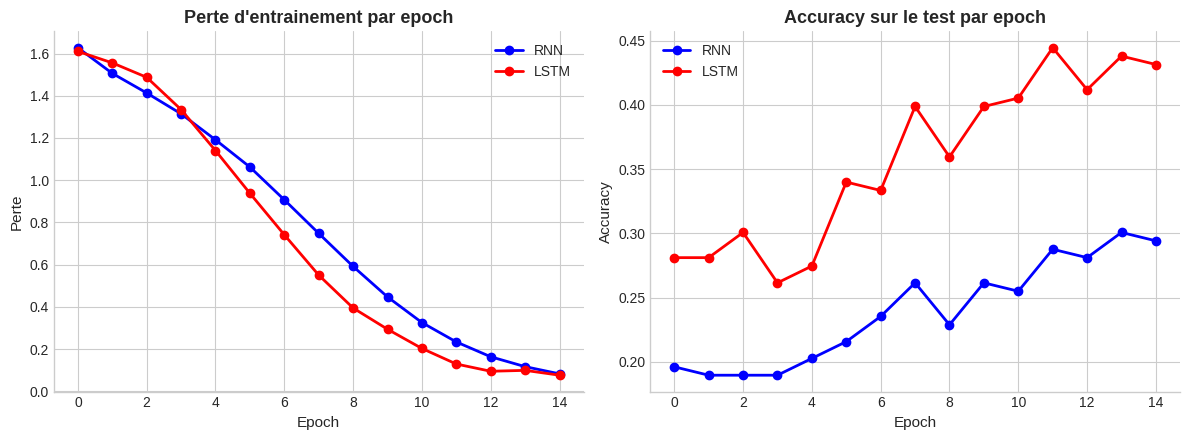

In [ ]:
plt.style.use('seaborn-v0_8-whitegrid')

couleur_rnn = 'blue'
couleur_lstm = 'red'

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(historique_rnn["train_loss"], label="RNN", color=couleur_rnn, marker='o', linewidth=2)
axes[0].plot(historique_lstm["train_loss"], label="LSTM", color=couleur_lstm, marker='o', linewidth=2)
axes[0].set_title("Perte d'entrainement par epoch", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Perte", fontsize=11)
axes[0].legend(frameon=False)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

axes[1].plot(historique_rnn["test_accuracy"], label="RNN", color=couleur_rnn, marker='o', linewidth=2)
axes[1].plot(historique_lstm["test_accuracy"], label="LSTM", color=couleur_lstm, marker='o', linewidth=2)
axes[1].set_title("Accuracy sur le test par epoch", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Accuracy", fontsize=11)
axes[1].legend(frameon=False)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


Le grand ecart entre la baisse de la perte (train) et la faible hausse de l'accuracy (test)

confirme le sur-apprentissage pour les deux modeles

## 12. Evaluation finale : accuracy, precision, rappel, F1 (macro et weighted)

Memes metriques que le TP1, pour une comparaison directe.

In [ ]:
def evaluer_modele(modele, dataloader):
    modele.eval()
    tous_preds, tous_labels = [], []
    with torch.no_grad():
        for batch in dataloader:
            x_batch, longueurs_batch, y_batch = batch
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            logits = modele(x_batch, longueurs_batch)
            preds = torch.argmax(logits, dim=1)
            tous_preds.extend(preds.cpu().numpy())
            tous_labels.extend(y_batch.cpu().numpy())
    return np.array(tous_labels), np.array(tous_preds)

y_true_rnn, y_pred_rnn = evaluer_modele(rnn_model, test_dataloader)
y_true_lstm, y_pred_lstm = evaluer_modele(lstm_model, test_dataloader)

#pour verifier si le modele predit bien plusieurs classes differentes?
print("Predictions RNN :", np.unique(y_pred_rnn, return_counts=True))
print("Predictions LSTM :", np.unique(y_pred_lstm, return_counts=True))

rows = []
for nom, y_true, y_pred in [("RNN", y_true_rnn, y_pred_rnn), ("LSTM", y_true_lstm, y_pred_lstm)]:
    rows.append({
        "modele": nom,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average='macro', zero_division=0),
        "rappel_macro": recall_score(y_true, y_pred, average='macro', zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average='macro', zero_division=0),
        "F1_weighted": f1_score(y_true, y_pred, average='weighted', zero_division=0),
    })
    print(f"\n=== {nom} ===")
    print(classification_report(y_true, y_pred, target_names=encodeur.classes_, zero_division=0))

pd.DataFrame(rows)


Predictions RNN : (array([0, 1, 2, 3, 4]), array([27, 22, 24, 31, 49]))
Predictions LSTM : (array([0, 1, 2, 3, 4]), array([27, 46, 11, 51, 18]))

=== RNN ===
                precision    recall  f1-score   support

DUKE VINCENTIO       0.52      0.42      0.47        33
    GLOUCESTER       0.36      0.20      0.26        40
      MENENIUS       0.21      0.20      0.20        25
     PETRUCHIO       0.19      0.22      0.21        27
         ROMEO       0.24      0.43      0.31        28

      accuracy                           0.29       153
     macro avg       0.31      0.30      0.29       153
  weighted avg       0.32      0.29      0.30       153


=== LSTM ===
                precision    recall  f1-score   support

DUKE VINCENTIO       0.41      0.33      0.37        33
    GLOUCESTER       0.39      0.45      0.42        40
      MENENIUS       0.45      0.20      0.28        25
     PETRUCHIO       0.43      0.81      0.56        27
         ROMEO       0.56      0.36     

,modele,accuracy,precision_macro,rappel_macro,F1_macro,F1_weighted
0,RNN,0.294118,0.305787,0.295007,0.289480,0.295020
1,LSTM,0.431373,0.448037,0.431058,0.412387,0.413028


Les prédictions couvrent bien les 5 classes pour les deux modèles et le LSTM, avec une accuracy de 0.431 et un F1 macro de 0.412 performe beaucoup mieux que le modèle RNN qui a une accuracy de 0.294 et un F1 macro de 0.289.

## 13. Matrice de confusion (meilleur modele)

Meme type de visualisation que le TP3 (heatmap seaborn), appliquee ici au meilleur des deux modeles recurrents.

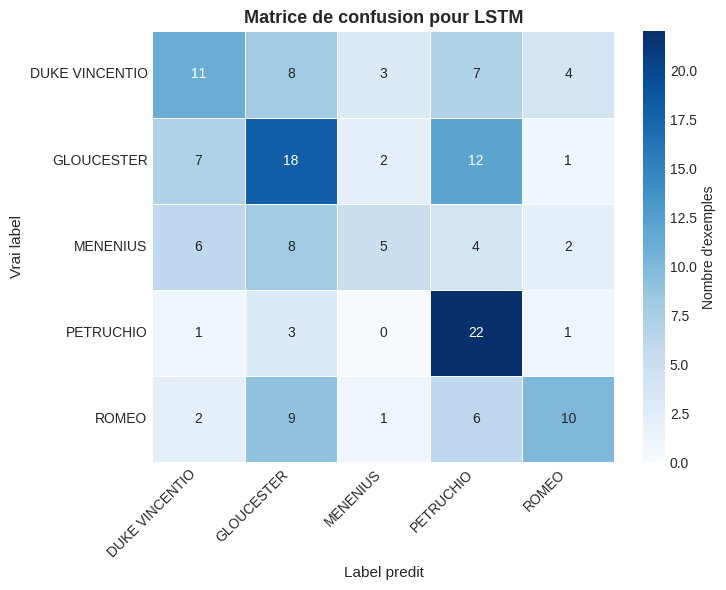

In [ ]:
#LSTM choisi car c'est meilleur en tous metric compare a RNN
meilleur_modele_dl = "LSTM"
y_true_meilleur, y_pred_meilleur = (y_true_lstm, y_pred_lstm) if meilleur_modele_dl == "LSTM" else (y_true_rnn, y_pred_rnn)

mat = confusion_matrix(y_true_meilleur, y_pred_meilleur)
df_cm = pd.DataFrame(mat, index=encodeur.classes_, columns=encodeur.classes_)

plt.figure(figsize=(7.5, 6))
sns.heatmap(
    df_cm, annot=True, fmt='d', cmap='Blues',
    linewidths=0.5, linecolor='white', cbar_kws={'label': "Nombre d'exemples"}
)
plt.title(f"Matrice de confusion pour {meilleur_modele_dl}", fontsize=13, fontweight='bold')
plt.ylabel("Vrai label", fontsize=11)
plt.xlabel("Label predit", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 14. Comparaison finale : TF-IDF classique (TP1) vs RNN vs LSTM

Resultats du TP1 (LogReg) reportes a cote des resultats du RNN et du LSTM.

In [ ]:
comparaison = pd.DataFrame([
    {"modele": "TF-IDF + LogReg (TP1)", "accuracy": 0.667, "F1_macro": 0.668, "F1_weighted": 0.667},
    {"modele": "RNN",  "accuracy": rows[0]["accuracy"], "F1_macro": rows[0]["F1_macro"], "F1_weighted": rows[0]["F1_weighted"]},
    {"modele": "LSTM", "accuracy": rows[1]["accuracy"], "F1_macro": rows[1]["F1_macro"], "F1_weighted": rows[1]["F1_weighted"]},
])
comparaison


,modele,accuracy,F1_macro,F1_weighted
0,TF-IDF + LogReg (TP1),0.667000,0.668000,0.667000
1,RNN,0.294118,0.289480,0.295020
2,LSTM,0.431373,0.412387,0.413028


Le pipeline classique du TP1 reste largement devant les deux modeles recurrents sur ce dataset


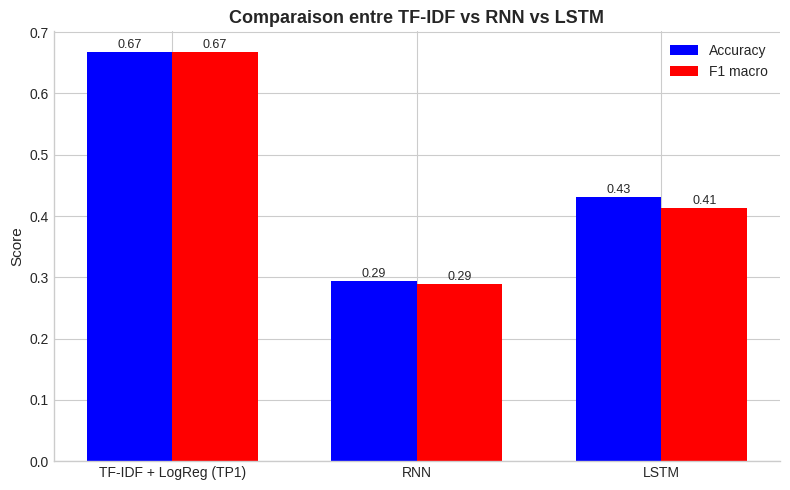

In [ ]:
#Visualisation entre tous les modeles
plt.style.use('seaborn-v0_8-whitegrid')

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparaison))
largeur = 0.35

barres_acc = ax.bar(x - largeur/2, comparaison['accuracy'], largeur, label='Accuracy', color='blue')
barres_f1 = ax.bar(x + largeur/2, comparaison['F1_macro'], largeur, label='F1 macro', color='red')

ax.set_xticks(x)
ax.set_xticklabels(comparaison['modele'])
ax.set_ylabel("Score", fontsize=11)
ax.set_title("Comparaison entre TF-IDF vs RNN vs LSTM", fontsize=13, fontweight='bold')
ax.legend(frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for barres in [barres_acc, barres_f1]:
    for barre in barres:
        hauteur = barre.get_height()
        ax.annotate(f'{hauteur:.2f}', xy=(barre.get_x() + barre.get_width()/2, hauteur),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.show()


## 15. Analyse - le deep learning bat-il le pipeline classique ?

Questions a discuter, en s'appuyant sur les vrais chiffres obtenus ci-dessus :

1. Le RNN et le LSTM battent-ils le pipeline TF-IDF + LogReg du TP1? De combien?
2. Le LSTM fait il mieux que le RNN simple? Est ce coherent avec ce qui a ete vu en cours sur le vanishing gradient?
3. Avec seulement 761 exemples au total et des repliques courtes (mediane 14 mots) quel pipeline a structurellement l'avantage et pourquoi?
4. Que faudrait il changer (plus de donnees, embeddings pre-entraines, bidirectionnalite, plus de couches) pour donner une meilleure chance au RNN et LSTM?

> *Mon Reponse:*
>
> 1. Ni le RNN ni le LSTM ne battent le pipeline TF-IDF + LogReg du TP1 (66.7% accuracy, F1 macro 0.668). Le LSTM atteint 43.1% d'accuracy (F1 macro 0,412) et le RNN seulement 29.4% (F1 macro 0.289) : les deux sont nettement en dessous.
>
> 2. Oui, le LSTM fait clairement mieux que le RNN simple (F1 macro 0.412 contre 0.89). C'est coherent avec le cours que le RNN simple souffre davantage du vanishing gradient et retient moins bien l'information au fil de la sequence. Alors que les portes du LSTM lui permettent de mieux conserver un signal utile.
>
> 3. Avec seulement 761 exemples et des repliques courtes (mediane 14 mots). Le pipeline classique a l'avantage structurel. Le TF-IDF encode directement des mots precis et discriminants. Mais le RNN et LSTM doit apprendre des embeddings et des dependances sequentielles a partir de tres peu de donnees ce qui est beaucoup plus gourmand en exemples.
>
> 4. Pour donner une meilleure chance au RNN/LSTM, il faudrait plus de donnees d'entrainement, utiliser des embeddings pre-entraines (comme GloVe ou Word2Vec) plutot que de les apprendre depuis zero, essayer une architecture bidirectionnelle (BiLSTM), et ajouter du dropout pour limiter le sur-apprentissage observe en section 11.